# EAGLE · 01 — Generar base geográfica de celdas

Genera cuadrados de **10 × 10 km por defecto** (configurable), con un identificador permanente, geometría, coordenadas y superficie terrestre.

**Cobertura:** España peninsular, Canarias, Baleares, Ceuta, Melilla, Portugal continental y Andorra. Gibraltar se incorpora si la fuente pública dispone de él. No incorpora los archipiélagos portugueses de Azores o Madeira. Los pequeños islotes o plazas de soberanía dependen de la escala de la cartografía publicada.

**Proyecciones:** los cuadrados se construyen en **EPSG:3035** (sistema métrico europeo). Se guardan puntos de referencia en WGS84 (latitud y longitud). En los bordes de costa, las celdas se conservan como cuadrados completos, acompañados de su superficie terrestre real.

**Ejecución:** este cuaderno solo debe utilizarse cuando necesitemos crear o reconstruir la base. Los demás miembros del equipo solo necesitan recibir `data/base/eagle_territorio.gpkg`.

> **Instalación (solo si faltan paquetes):** ejecuta en una celda `%pip install geopandas shapely pyproj pyogrio requests matplotlib numpy pandas` y reinicia el kernel.
> Requiere conexión a Internet **solo la primera vez** para obtener los límites territoriales; se guardan en `data/fuentes_geograficas/`. Los cálculos posteriores funcionan sin Internet cuando ya existen los archivos descargados.


## 1 · Configuración

**Cambia únicamente `TAMANO_CELDA_KM` para modificar la resolución.** Al cambiarla obtendrás una malla y unos identificadores distintos: no mezcles indicadores calculados para versiones diferentes.

In [1]:
from pathlib import Path

# CAMBIA ESTA LÍNEA PARA DEFINIR EL TAMAÑO DE LOS CUADRADOS =====
TAMANO_CELDA_KM = 10  # por ejemplo: 5, 10, 20  (10 quiere decir 10x10km es decir 100km^2)

CRS_MALLA = 'EPSG:3035'
CRS_GPS = 'EPSG:4326'
BASE_DIR = Path('data')
CACHE_DIR = BASE_DIR / 'fuentes_geograficas'
OUT_DIR = BASE_DIR / 'base'
EXPORTAR_CSV = True
INCLUIR_GIBRALTAR_SI_DISPONIBLE = True

assert TAMANO_CELDA_KM > 0
PASO_M = int(TAMANO_CELDA_KM * 1000)
assert PASO_M == TAMANO_CELDA_KM * 1000, 'El tamaño debe producir un número entero de metros.'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Resolución: {TAMANO_CELDA_KM} × {TAMANO_CELDA_KM} km')

Resolución: 10 × 10 km


## 2 · Obtener límites administrativos

Utilizamos la API pública de **geoBoundaries**, que distribuye polígonos de países y divisiones administrativas. España se descarga a nivel de comunidad autónoma (ADM1), para identificar las ciudades autónomas y archipiélagos. Se valida la presencia de todos los territorios solicitados. La precisión cartográfica depende de la versión de origen.

In [2]:
import json
import re
import unicodedata
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import box
from shapely.ops import unary_union
from pyproj import Transformer
import matplotlib.pyplot as plt

print('GeoPandas:', gpd.__version__, '| Shapely:', shapely.__version__)

def obtener_geoboundaries(codigo, nivel='ADM0', opcional=False):
    destino = CACHE_DIR / f'{codigo}_{nivel}.geojson'
    if not destino.exists():
        api = f'https://www.geoboundaries.org/api/current/gbOpen/{codigo}/{nivel}/'
        try:
            respuesta = requests.get(api, timeout=45)
            respuesta.raise_for_status()
            metadatos = respuesta.json()
            url = (metadatos.get('simplifiedGeometryGeoJSON')
                   or metadatos.get('gjDownloadURL'))
            if not url:
                raise ValueError(f'No se encontró un enlace GeoJSON válido para {codigo}/{nivel}')
            descarga = requests.get(url, timeout=120)
            descarga.raise_for_status()
            contenido = descarga.json()
            if contenido.get('type') != 'FeatureCollection':
                raise ValueError('La descarga no es una FeatureCollection GeoJSON.')
            destino.write_text(json.dumps(contenido), encoding='utf-8')
        except Exception as exc:
            if opcional:
                print(f'Aviso: {codigo}/{nivel} no disponible: {exc}')
                return None
            raise RuntimeError(
                f'No se pudo obtener {codigo}/{nivel}. Revisa Internet o la API geoBoundaries. '
                'Si ya descargaste el archivo, colócalo en data/fuentes_geograficas. '
                f'Detalle: {exc}'
            ) from exc
    result = gpd.read_file(destino).to_crs(CRS_GPS)
    result = result.loc[result.geometry.notna() & ~result.geometry.is_empty].copy()
    return result

esp_adm1 = obtener_geoboundaries('ESP', 'ADM1')
prt_adm0 = obtener_geoboundaries('PRT', 'ADM0')
and_adm0 = obtener_geoboundaries('AND', 'ADM0')
gib_adm0 = (obtener_geoboundaries('GIB', 'ADM0', opcional=True)
            if INCLUIR_GIBRALTAR_SI_DISPONIBLE else None)

print('Regiones españolas:', len(esp_adm1))
print('Campos españoles:', list(esp_adm1.columns))

GeoPandas: 1.2.0 | Shapely: 2.2.0
Regiones españolas: 19
Campos españoles: ['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType', 'geometry']


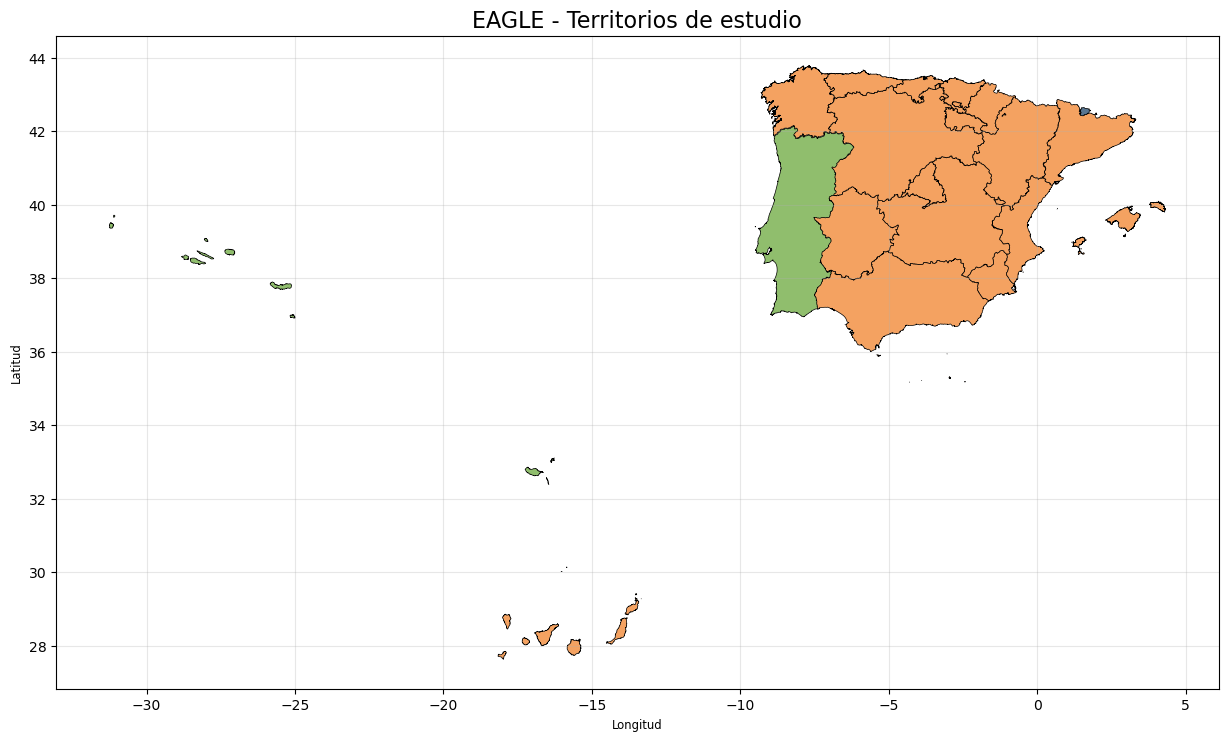

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 12))

# España
esp_adm1.plot(
    ax=ax,
    color="#f4a261",
    edgecolor="black",
    linewidth=0.5,
    label="España"
)

# Portugal
prt_adm0.plot(
    ax=ax,
    color="#90be6d",
    edgecolor="black",
    linewidth=0.5
)

# Andorra
and_adm0.plot(
    ax=ax,
    color="#577590",
    edgecolor="black",
    linewidth=0.5
)

# Gibraltar (si está disponible)
if gib_adm0 is not None:
    gib_adm0.plot(
        ax=ax,
        color="#b56576",
        edgecolor="black",
        linewidth=0.5
    )

ax.set_title(
    "EAGLE - Territorios de estudio",
    fontsize=16
)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.grid(alpha=0.3)

plt.show()

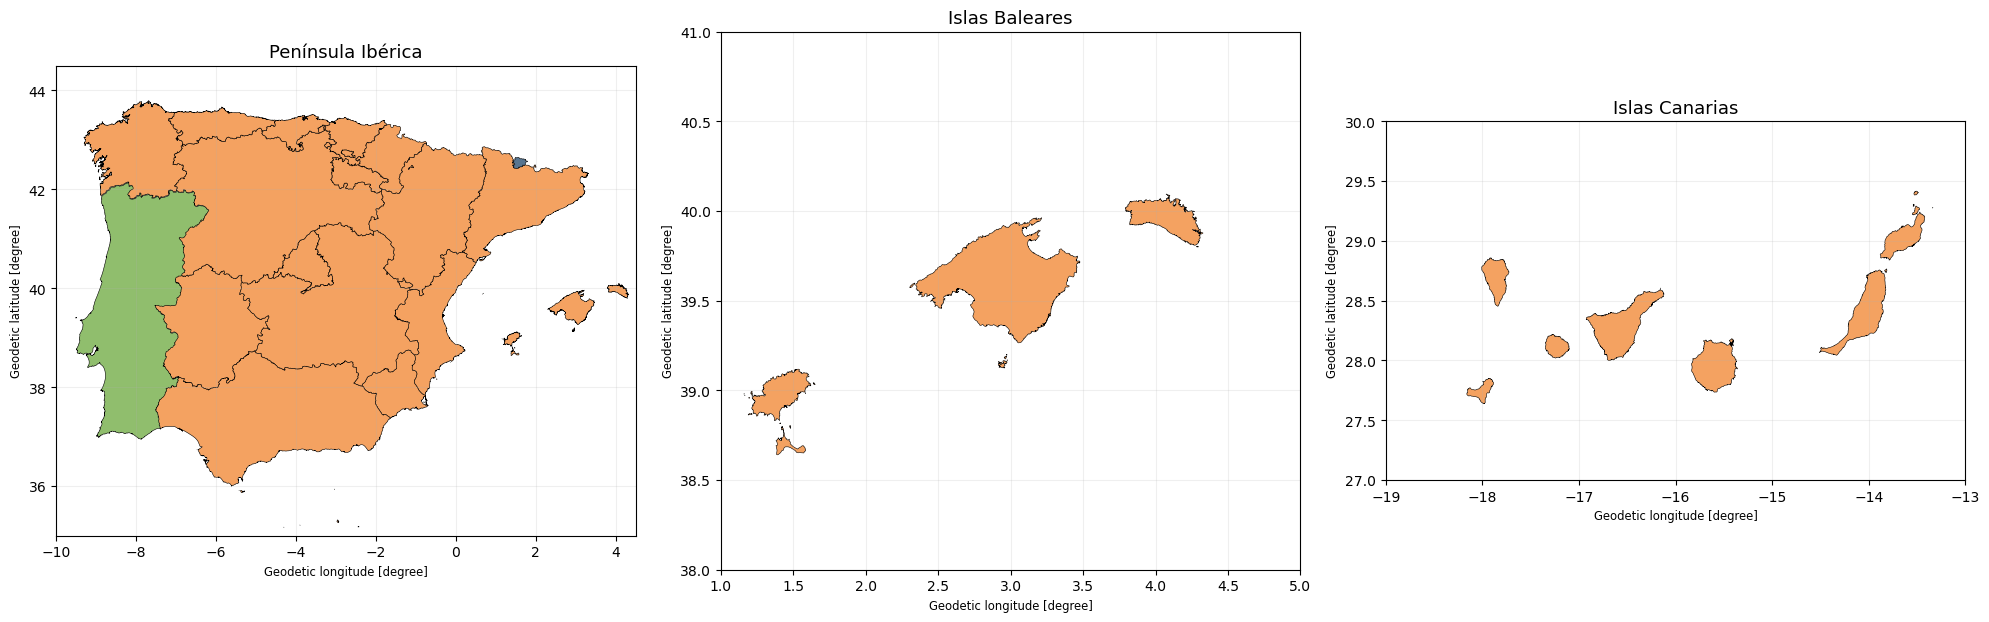

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

territorios = [
    ([-10, 4.5, 35, 44.5], "Península Ibérica"),
    ([1, 5, 38, 41], "Islas Baleares"),
    ([-19, -13, 27, 30], "Islas Canarias")
]

for ax, (limites, titulo) in zip(axes, territorios):

    esp_adm1.plot(
        ax=ax,
        color="#f4a261",
        edgecolor="black",
        linewidth=0.4
    )

    prt_adm0.plot(
        ax=ax,
        color="#90be6d",
        edgecolor="black",
        linewidth=0.4
    )

    and_adm0.plot(
        ax=ax,
        color="#577590",
        edgecolor="black",
        linewidth=0.4
    )

    if gib_adm0 is not None:
        gib_adm0.plot(
            ax=ax,
            color="#b56576",
            edgecolor="black",
            linewidth=0.4
        )

    ax.set_xlim(limites[0], limites[1])
    ax.set_ylim(limites[2], limites[3])

    ax.set_title(titulo, fontsize=13)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

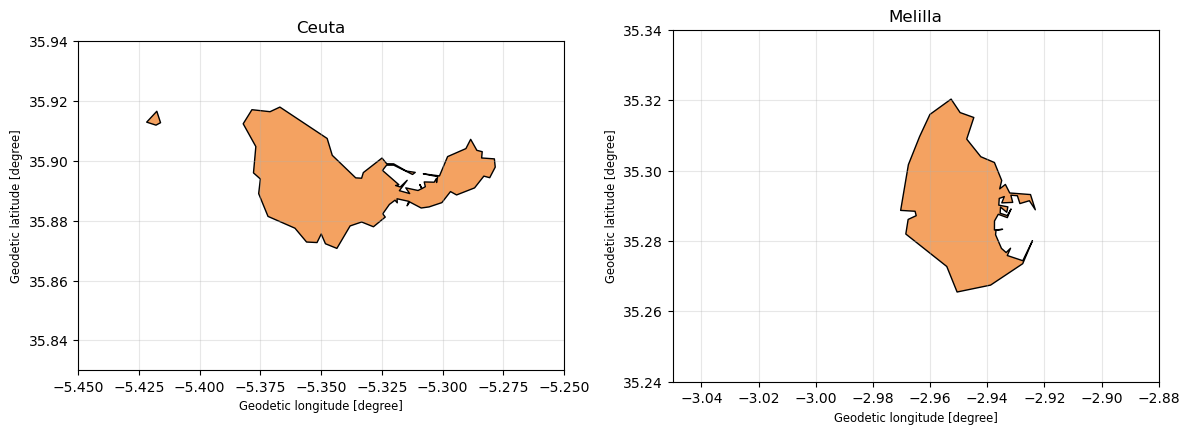

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ciudades = [
    ([-5.45, -5.25, 35.83, 35.94], "Ceuta"),
    ([-3.05, -2.88, 35.24, 35.34], "Melilla")
]

for ax, (limites, titulo) in zip(axes, ciudades):

    esp_adm1.plot(
        ax=ax,
        color="#f4a261",
        edgecolor="black"
    )

    ax.set_xlim(limites[0], limites[1])
    ax.set_ylim(limites[2], limites[3])

    ax.set_title(titulo)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3 · Preparar territorios y verificar cobertura

In [6]:
def nombre_limpio(valor):
    texto = unicodedata.normalize('NFKD', str(valor))
    return ''.join(c for c in texto if not unicodedata.combining(c)).lower().strip()

def clasificar_espana(nombre):
    s = nombre_limpio(nombre)
    if 'canar' in s: return 'Canarias'
    if 'balear' in s: return 'Baleares'
    if 'ceuta' in s: return 'Ceuta'
    if 'melilla' in s: return 'Melilla'
    return 'España peninsular'

col_nombre = next((c for c in ['shapeName', 'name', 'NAME_1', 'region']
                   if c in esp_adm1.columns), None)
if col_nombre is None:
    raise ValueError('No se encuentra la columna de nombres de regiones. Consulta esp_adm1.columns.')

esp = esp_adm1.copy()
esp['territorio'] = esp[col_nombre].map(clasificar_espana)
esp['pais'] = 'España'

# Los datos de Ceuta, Melilla e islas se comprueban antes de crear la malla.
obligatorios = {'España peninsular', 'Canarias', 'Baleares', 'Ceuta', 'Melilla'}
faltantes = obligatorios - set(esp['territorio'])
if faltantes:
    raise RuntimeError(
        f'La cartografía ADM1 no incluye {sorted(faltantes)}. '
        'No crearemos una malla incompleta. Usa otra versión/fuente administrativa.'
    )

# Excluir Madeira/Azores de Portugal, conservando solo polígonos continentales.
prt_partes = prt_adm0.explode(index_parts=False).reset_index(drop=True)
prt_partes = prt_partes.loc[prt_partes.geometry.representative_point().x > -12.5].copy()
if prt_partes.empty:
    raise RuntimeError('No se ha podido aislar Portugal continental.')
prt_partes['territorio'] = 'Portugal continental'
prt_partes['pais'] = 'Portugal'

and_ = and_adm0.copy()
and_['territorio'] = 'Andorra'
and_['pais'] = 'Andorra'

capas = [esp[['pais', 'territorio', 'geometry']],
         prt_partes[['pais', 'territorio', 'geometry']],
         and_[['pais', 'territorio', 'geometry']]]
if gib_adm0 is not None and not gib_adm0.empty:
    gib_ = gib_adm0.copy()
    gib_['territorio'] = 'Gibraltar'
    gib_['pais'] = 'Gibraltar'
    capas.append(gib_[['pais', 'territorio', 'geometry']])

zonas = gpd.GeoDataFrame(pd.concat(capas, ignore_index=True),
                         geometry='geometry', crs=CRS_GPS)
zonas_m = zonas.to_crs(CRS_MALLA)
# Reparar geometrías inválidas, sin eliminar polígonos pequeños.
zonas_m['geometry'] = shapely.make_valid(zonas_m.geometry.to_numpy())
zonas_m = zonas_m.loc[~zonas_m.geometry.is_empty].copy()

# Agrupación por territorio para no recorrer el enorme rectángulo entre Canarias y la península.
zonas_agrupadas = zonas_m.dissolve(by=['pais', 'territorio'], as_index=False)
area_unida = shapely.union_all(zonas_agrupadas.geometry.to_numpy())
print('Territorios representados:')
print(zonas_agrupadas[['pais', 'territorio']].to_string(index=False))

Territorios representados:
     pais           territorio
  Andorra              Andorra
   España             Baleares
   España             Canarias
   España                Ceuta
   España    España peninsular
   España              Melilla
Gibraltar            Gibraltar
 Portugal Portugal continental


## 4 · Generación rápida de la cuadrícula

Se construye un rectángulo de búsqueda **para cada territorio** (en vez de utilizar una sola extensión que incluya el océano entre Canarias y la península). Las operaciones geométricas se ejecutan por lotes y los cuadrados compartidos entre territorios se eliminan por identificador.

In [7]:
def construir_candidatos(geometrias, paso_m):
    ids = set()
    for geom in geometrias:
        xmin, ymin, xmax, ymax = geom.bounds
        cols = np.arange(int(np.floor(xmin / paso_m)),
                         int(np.ceil(xmax / paso_m)), dtype=np.int64)
        rows = np.arange(int(np.floor(ymin / paso_m)),
                         int(np.ceil(ymax / paso_m)), dtype=np.int64)
        cc, rr = np.meshgrid(cols, rows)
        cc, rr = cc.ravel(), rr.ravel()
        polys = shapely.box(cc*paso_m, rr*paso_m,
                            (cc+1)*paso_m, (rr+1)*paso_m)
        mask = shapely.intersects(polys, geom)
        ids.update(zip(rr[mask].tolist(), cc[mask].tolist()))
    return sorted(ids)

indices = construir_candidatos(zonas_agrupadas.geometry, PASO_M)
filas = np.array([v[0] for v in indices], dtype=np.int64)
cols = np.array([v[1] for v in indices], dtype=np.int64)
cuadrados = shapely.box(cols*PASO_M, filas*PASO_M,
                        (cols+1)*PASO_M, (filas+1)*PASO_M)
# Quitar celdas que solo toquen el territorio en un punto o una línea.
interseccion = shapely.intersection(cuadrados, area_unida)
superficie = shapely.area(interseccion)
mascara = superficie > 1e-4
filas, cols, cuadrados = filas[mascara], cols[mascara], cuadrados[mascara]
interseccion, superficie = interseccion[mascara], superficie[mascara]
print(f'Celdas terrestres: {len(cuadrados):,}')

# Punto representativo en tierra y centro geométrico (puede estar en el mar).
puntos = shapely.point_on_surface(interseccion)
centros = shapely.centroid(cuadrados)
tr = Transformer.from_crs(CRS_MALLA, CRS_GPS, always_xy=True)
longitud, latitud = tr.transform(shapely.get_x(puntos), shapely.get_y(puntos))

celdas = gpd.GeoDataFrame({
    'celda_id': [f"E.{r - filas.min() + 1:03d}.{c - cols.min() + 1:03d}" for r, c in zip(filas, cols)],
    'fila': filas, 'columna': cols,
    'tamano_km': TAMANO_CELDA_KM,
    'superficie_celda_km2': (PASO_M/1000)**2,
    'superficie_tierra_km2': superficie/1e6,
    'porcentaje_tierra': superficie/PASO_M**2*100,
    'centro_x_m': shapely.get_x(centros),
    'centro_y_m': shapely.get_y(centros),
    'punto_tierra_x_m': shapely.get_x(puntos),
    'punto_tierra_y_m': shapely.get_y(puntos),
    'latitud': latitud, 'longitud': longitud,
}, geometry=cuadrados, crs=CRS_MALLA)
assert celdas.celda_id.is_unique
print(celdas[['celda_id','latitud','longitud','superficie_tierra_km2']].head())

Celdas terrestres: 6,356
    celda_id    latitud   longitud  superficie_tierra_km2
0  E.001.025  27.739800 -15.600963               0.884545
1  E.001.026  27.744500 -15.582680               4.799401
2  E.001.037  28.076278 -14.444625               7.422027
3  E.001.038  28.073885 -14.373911              60.599222
4  E.001.039  28.094737 -14.300302              48.387500


## 5 · Asignar territorio dominante a cada celda

In [8]:
# Cruce espacial: solo se evalúan las parejas celda/territorio que se tocan.
parejas = gpd.sjoin(celdas[['geometry']],
                    zonas_agrupadas[['pais','territorio','geometry']],
                    how='inner', predicate='intersects')
parejas['index_right'] = parejas['index_right'].astype(int)
area_por_pareja = shapely.area(shapely.intersection(
    celdas.geometry.loc[parejas.index].to_numpy(),
    zonas_agrupadas.geometry.iloc[parejas.index_right.to_numpy()].to_numpy()
))
parejas['area_en_celda'] = area_por_pareja
parejas = parejas.loc[parejas.area_en_celda > 0].copy()
dominantes = parejas.sort_values('area_en_celda').groupby(level=0).tail(1)
celdas['pais'] = dominantes['pais']
celdas['territorio'] = dominantes['territorio']
assert celdas.pais.notna().all(), 'Hay celdas sin territorio asignado.'
assert celdas.celda_id.is_unique

print(celdas.groupby(['pais','territorio']).size().to_string())
territorios_en_malla = set(celdas['territorio'])
assert {'Canarias','Baleares','Ceuta','Melilla'}.issubset(territorios_en_malla), (
    'Falta algún territorio insular o ciudad autónoma en la malla'
)
print('Verificación de cobertura: OK')

pais       territorio          
Andorra    Andorra                    7
España     Baleares                  95
           Canarias                 153
           Ceuta                      2
           España peninsular       5147
           Melilla                    6
Gibraltar  Gibraltar                  1
Portugal   Portugal continental     945
Verificación de cobertura: OK


## 6 · Exportar la base que compartiremos

El GeoPackage contiene una tabla espacial `celdas` con el cuadrado completo. El archivo CSV es un suplemento para inspecciones rápidas. **No se añaden indicadores vacíos en la base original**, para que cada equipo los calcule en archivos vinculados por `celda_id`.

In [9]:
import json

ruta_gpkg = OUT_DIR / 'eagle_territorio.gpkg'
ruta_csv = OUT_DIR / 'eagle_territorio.csv'
ruta_metadata = OUT_DIR / 'eagle_territorio_metadata.json'

# =====================================================
# 1. SELECCIONAR COLUMNAS DE LA BASE DE DATOS
# =====================================================

COLUMNAS_EXPORTAR = [
    "celda_id",
    "pais",
    "territorio",
    "latitud",
    "longitud",
    "superficie_tierra_km2",
    "porcentaje_tierra",
    "geometry"
]

# Crear tabla con las columnas seleccionadas
celdas_exportar = celdas[COLUMNAS_EXPORTAR].copy()

# =====================================================
# 2. EXPORTAR BASE DE DATOS
# =====================================================

# Eliminar la base anterior si existe
if ruta_gpkg.exists():
    ruta_gpkg.unlink()

# CAPA 1: Guardar las celdas de EAGLE
celdas_exportar.to_file(
    ruta_gpkg,
    layer="celdas",
    driver="GPKG",
    engine="pyogrio"
)

# CAPA 2: Guardar los límites reales del territorio
zonas_agrupadas.to_crs(celdas.crs).to_file(
    ruta_gpkg,
    layer="limites_territoriales",
    driver="GPKG",
    engine="pyogrio",
    append=True
)

# Exportar también en CSV (sin geometría)
if EXPORTAR_CSV:
    celdas_exportar.drop(
        columns="geometry"
    ).to_csv(
        ruta_csv,
        index=False
    )

# =====================================================
# 3. GUARDAR METADATOS
# =====================================================

metadata = {
    'nombre': 'EAGLE — malla territorial',
    'tamano_celda_km': TAMANO_CELDA_KM,
    'crs_malla': CRS_MALLA,
    'crs_coordenadas': CRS_GPS,
    'num_celdas': len(celdas_exportar),
    'columnas': COLUMNAS_EXPORTAR,
    'pais_territorio': (
        celdas_exportar.groupby(['pais', 'territorio'])
        .size()
        .rename('celdas')
        .reset_index()
        .to_dict('records')
    ),
    'fuente_limites': 'geoBoundaries gbOpen, ESP ADM1; PRT/AND/GIB ADM0',
    'nota': 'Los polígonos son cuadrados íntegros. Las celdas costeras incluyen mar.'
}

ruta_metadata.write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding='utf-8'
)

# =====================================================
# 4. COMPROBAR RESULTADOS
# =====================================================

print("Guardado:", ruta_gpkg.resolve())
print("Celdas:", len(celdas_exportar))
print("Columnas:", len(celdas_exportar.columns))

print("\nColumnas exportadas:")
print(celdas_exportar.columns.tolist())

print("\nCapas del GeoPackage:")
print(gpd.list_layers(ruta_gpkg))

display(celdas_exportar.drop(columns="geometry").head())

print("\nIMPORTANTE: comparte el GeoPackage con tus compañeros.")

Guardado: C:\workspace\EAGLE\Cudricula\data\base\eagle_territorio.gpkg
Celdas: 6356
Columnas: 8

Columnas exportadas:
['celda_id', 'pais', 'territorio', 'latitud', 'longitud', 'superficie_tierra_km2', 'porcentaje_tierra', 'geometry']

Capas del GeoPackage:
                    name geometry_type
0                 celdas       Polygon
1  limites_territoriales  MultiPolygon


,celda_id,pais,territorio,latitud,longitud,superficie_tierra_km2,porcentaje_tierra
0,E.001.025,España,Canarias,27.739800,-15.600963,0.884545,0.884545
1,E.001.026,España,Canarias,27.744500,-15.582680,4.799401,4.799401
2,E.001.037,España,Canarias,28.076278,-14.444625,7.422027,7.422027
3,E.001.038,España,Canarias,28.073885,-14.373911,60.599222,60.599222
4,E.001.039,España,Canarias,28.094737,-14.300302,48.387500,48.387500



IMPORTANTE: comparte el GeoPackage con tus compañeros.


## 7 · Validación independiente y mapa de control

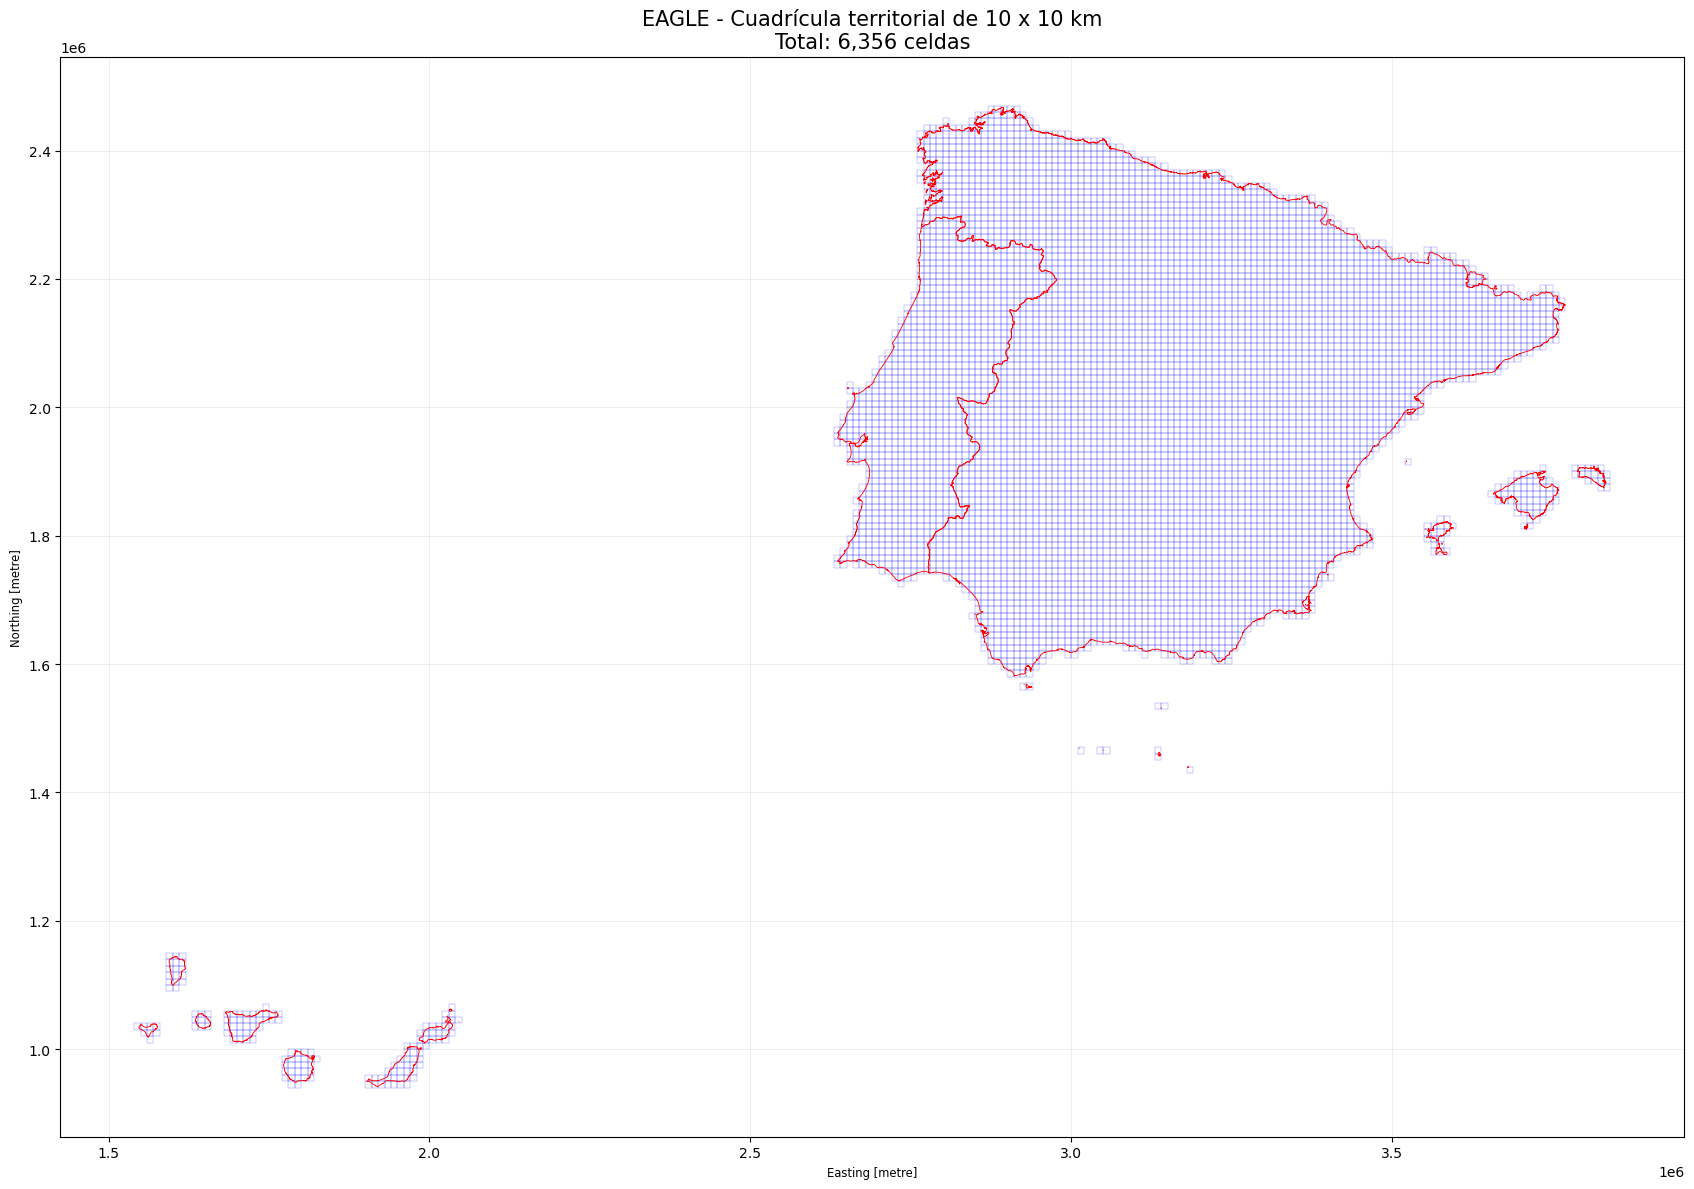

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(18, 12))

# Dibujar todos los cuadrados
celdas.boundary.plot(
    ax=ax,
    color="blue",
    linewidth=0.15
)

# Dibujar los límites terrestres
zonas_agrupadas.boundary.plot(
    ax=ax,
    color="red",
    linewidth=0.6
)

ax.set_title(
    f"EAGLE - Cuadrícula territorial de {TAMANO_CELDA_KM} x {TAMANO_CELDA_KM} km\n"
    f"Total: {len(celdas):,} celdas",
    fontsize=15
)

ax.set_aspect("equal")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

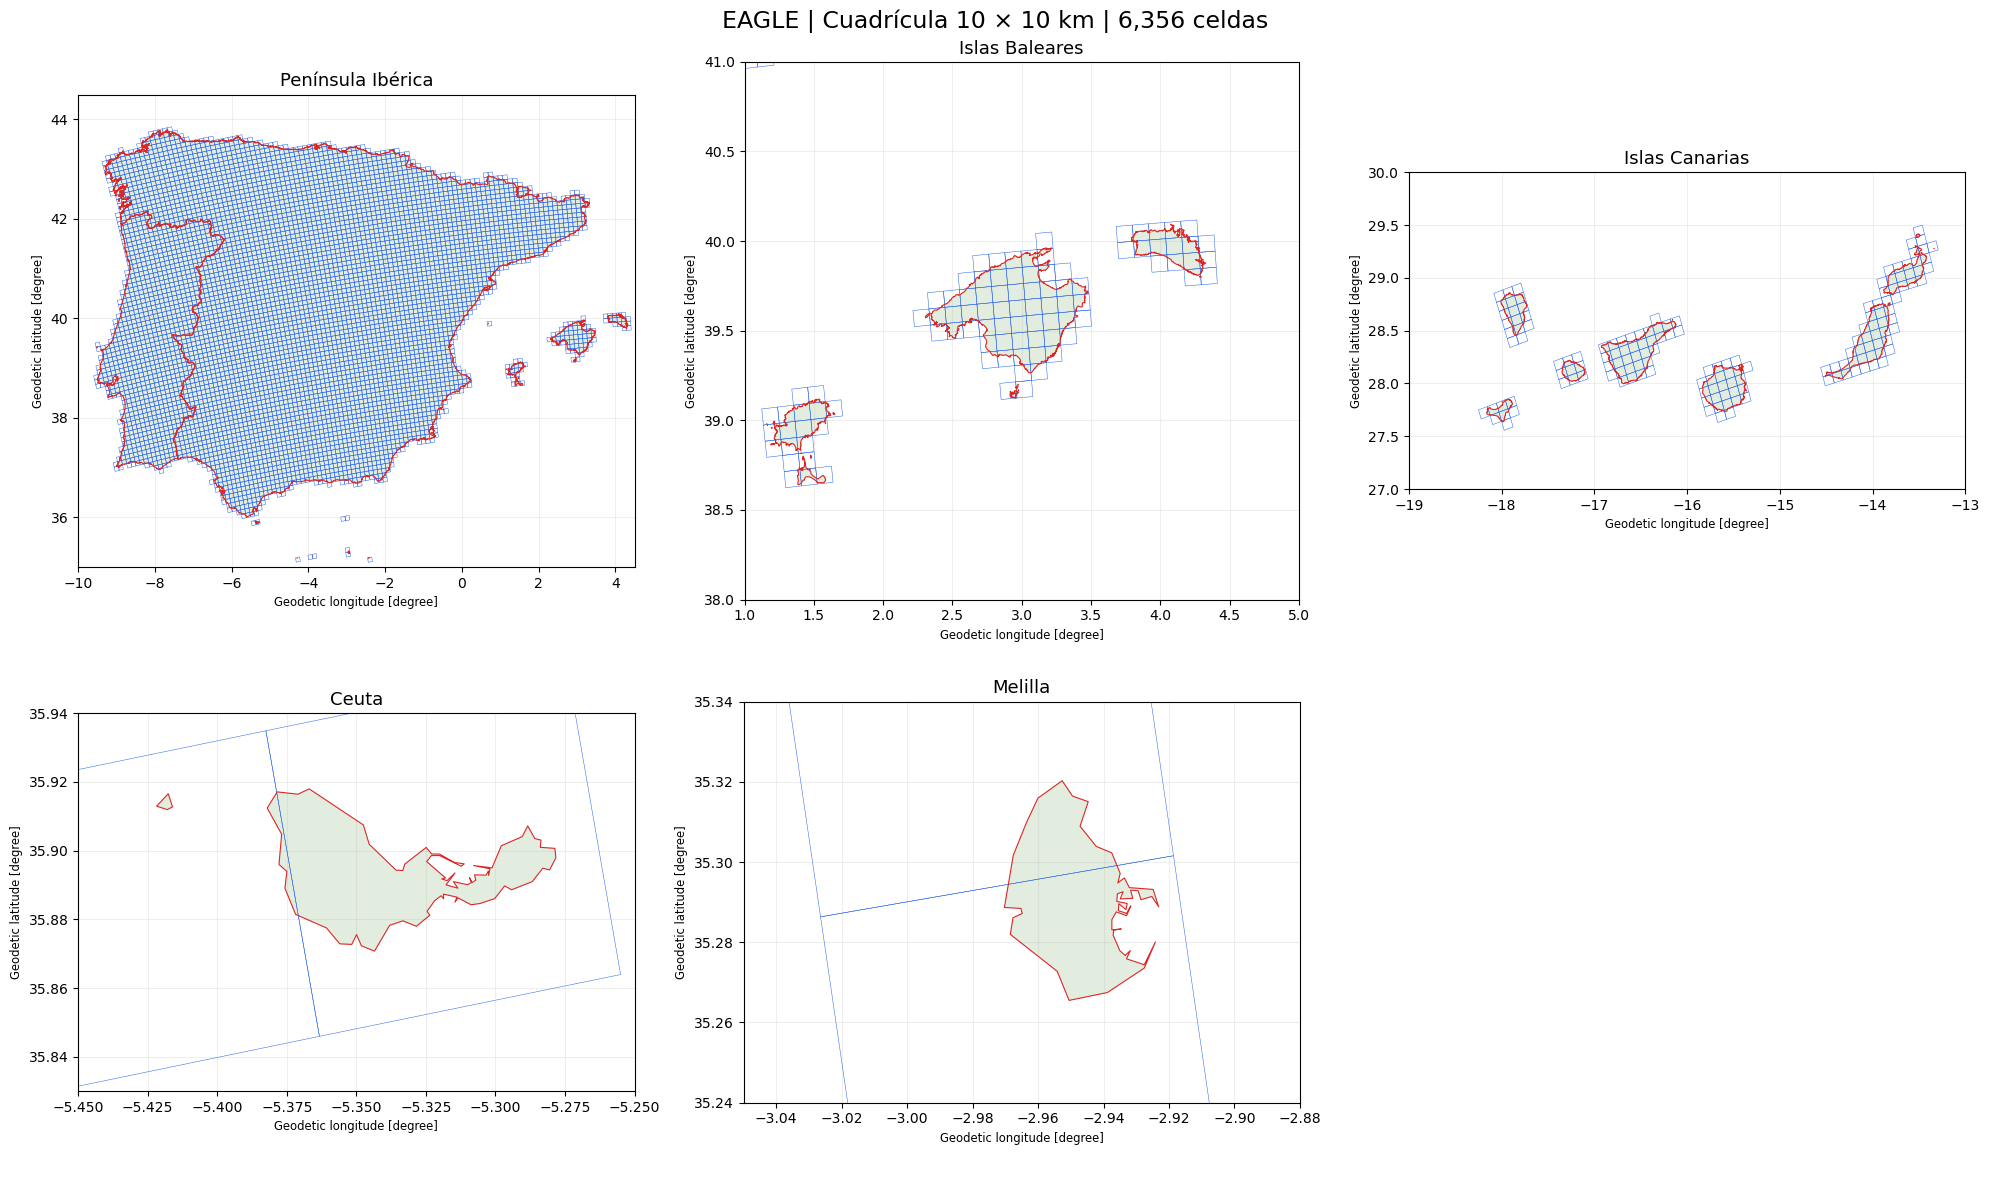

In [11]:
import matplotlib.pyplot as plt

# Proyectar temporalmente para visualizar en lat/lon
celdas_geo = celdas.to_crs("EPSG:4326")
territorio_geo = zonas_agrupadas.to_crs("EPSG:4326")

# Límites: [longitud_min, longitud_max, latitud_min, latitud_max]
regiones = {
    "Península Ibérica": (-10, 4.5, 35, 44.5),
    "Islas Baleares": (1, 5, 38, 41),
    "Islas Canarias": (-19, -13, 27, 30),
    "Ceuta": (-5.45, -5.25, 35.83, 35.94),
    "Melilla": (-3.05, -2.88, 35.24, 35.34)
}

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for ax, (nombre, limites) in zip(axes, regiones.items()):

    xmin, xmax, ymin, ymax = limites

    # Seleccionar solo las geometrías de esta región
    celdas_region = celdas_geo.cx[xmin:xmax, ymin:ymax]
    territorio_region = territorio_geo.cx[xmin:xmax, ymin:ymax]

    # Fondo terrestre
    territorio_region.plot(
        ax=ax,
        color="#e2eddf",
        edgecolor="none"
    )

    # Cuadrícula
    celdas_region.boundary.plot(
        ax=ax,
        color="#2563eb",
        linewidth=0.35
    )

    # Contornos territoriales
    territorio_region.boundary.plot(
        ax=ax,
        color="#dc2626",
        linewidth=0.8
    )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(nombre, fontsize=13)
    ax.grid(alpha=0.2)

# Ocultar gráfico sobrante
for ax in axes[len(regiones):]:
    ax.axis("off")

fig.suptitle(
    f"EAGLE | Cuadrícula {TAMANO_CELDA_KM} × {TAMANO_CELDA_KM} km "
    f"| {len(celdas):,} celdas",
    fontsize=17
)

plt.tight_layout()
plt.show()